# HandPilot Car — Model Sonuçları

El hareketleriyle (gaz, fren, sol, sağ) araç kontrolü için eğitilen modellerin test sonuçları.

## 1. Modeller

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
COLORS = ["#1f6feb", "#6e7781", "#d29922", "#2da44e", "#a371f7"]

modeller = pd.DataFrame([
    ["Furkan", "MLP (128-64), v2", "21 el noktası, 76 özellik", "models/furkan/v2_landmark_mlp/landmark_mlp.keras"],
    ["Hazal",  "CNN (MobileNetV3Small)", "El görüntüsü, 192×192", "models/hazal/final_model.keras"],
    ["Sibel",  "CNN (MobileNetV3Small)", "El görüntüsü, 160×160", "models/sibel/HandPilot_CNN_Model_Paketi.zip"],
    ["Sinem",  "MLP (128-64)",           "21 el noktası, 76 özellik", "models/sinem/best.keras"],
    ["Reyyan", "MLP",                    "21 el noktası, 63 özellik", "models/reyyan/best_mlp.keras"],
], columns=["Model", "Mimari", "Girdi", "Repodaki dosya"]).set_index("Model")
modeller

,Mimari,Girdi,Repodaki dosya
Model,,,
Furkan,"MLP (128-64), v2","21 el noktası, 76 özellik",models/furkan/v2_landmark_mlp/landmark_mlp.keras
Hazal,CNN (MobileNetV3Small),"El görüntüsü, 192×192",models/hazal/final_model.keras
Sibel,CNN (MobileNetV3Small),"El görüntüsü, 160×160",models/sibel/HandPilot_CNN_Model_Paketi.zip
Sinem,MLP (128-64),"21 el noktası, 76 özellik",models/sinem/best.keras
Reyyan,MLP,"21 el noktası, 63 özellik",models/reyyan/best_mlp.keras


## 2. Doğruluk değerleri

In [2]:
sonuc = pd.DataFrame([
    ["Furkan", 12492, 0.9951, 0.9933, 0.9937],
    ["Hazal",  1811, 0.9459, 0.9470, 0.9440],
    ["Sibel",  1558, 0.9872, 0.9883, 0.9860],
    ["Sinem",  2139, 0.9981, 0.9980, 0.9981],
    ["Reyyan", 12492, 0.9996, 0.9996, 0.9996],
], columns=["Model", "Test örneği", "Doğruluk", "Dengeli doğruluk", "Macro F1"]).set_index("Model")

tablo = sonuc.copy()
for c in ["Doğruluk", "Dengeli doğruluk", "Macro F1"]:
    tablo[c] = (100 * tablo[c]).map("%{:.2f}".format)
tablo

,Test örneği,Doğruluk,Dengeli doğruluk,Macro F1
Model,,,,
Furkan,12492,%99.51,%99.33,%99.37
Hazal,1811,%94.59,%94.70,%94.40
Sibel,1558,%98.72,%98.83,%98.60
Sinem,2139,%99.81,%99.80,%99.81
Reyyan,12492,%99.96,%99.96,%99.96


*Furkan'ın modeli, ilk CNN sürümünün (%94,59) ardından el noktası tabanlı mimariye geçirilerek geliştirilmiştir. Değerler 13 katlı kişi bazlı çapraz doğrulamanın (her katta bir kişi tamamen test için ayrılır) ortalamasıdır: %99,51 ± 0,95, en düşük kat %96,66.*

*Reyyan'ın modeli için ayrı bir test kümesi kaydı bulunmadığından değerleri tüm veri seti üzerinde ölçülmüştür.*

## 3. Grafikler

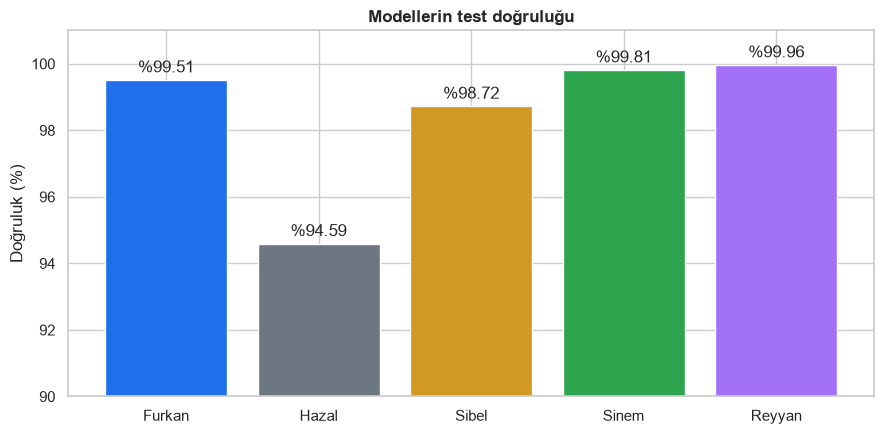

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(sonuc.index, 100 * sonuc["Doğruluk"], color=COLORS)
ax.bar_label(bars, labels=[f"%{100*v:.2f}" for v in sonuc["Doğruluk"]], padding=3)
ax.set_ylim(90, 101); ax.set_ylabel("Doğruluk (%)"); ax.set_title("Modellerin test doğruluğu", fontweight="bold")
plt.tight_layout(); plt.show()

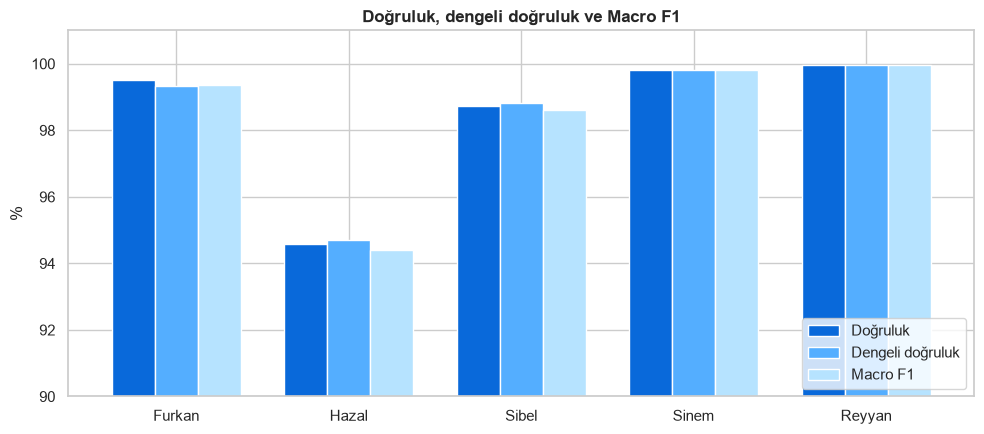

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
(100 * sonuc[["Doğruluk", "Dengeli doğruluk", "Macro F1"]]).plot.bar(ax=ax, color=["#0969da", "#54aeff", "#b6e3ff"], width=.75, rot=0)
ax.set_ylim(90, 101); ax.set_ylabel("%"); ax.set_xlabel(""); ax.set_title("Doğruluk, dengeli doğruluk ve Macro F1", fontweight="bold")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

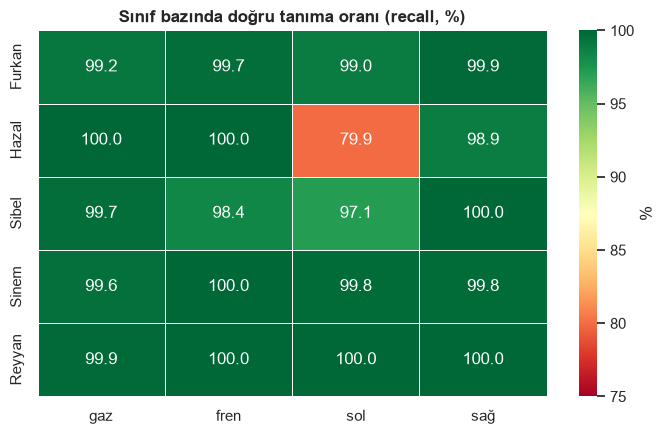

In [5]:
recall = pd.DataFrame({
    "gaz":  [0.992, 1.000, 0.997, 0.996, 0.999],
    "fren": [0.997, 1.000, 0.984, 1.000, 1.000],
    "sol":  [0.990, 0.799, 0.971, 0.998, 1.000],
    "sağ":  [0.999, 0.989, 1.000, 0.998, 1.000],
}, index=sonuc.index)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(100 * recall, annot=True, fmt=".1f", cmap="RdYlGn", vmin=75, vmax=100, linewidths=.5, ax=ax, cbar_kws={"label": "%"})
ax.set_title("Sınıf bazında doğru tanıma oranı (recall, %)", fontweight="bold"); ax.set_ylabel("")
plt.tight_layout(); plt.show()